# Результаты: Saluki 27B и medbot (Qwen3-4B + LoRA)

Ноутбук только читает сохранённые результаты из `results/` — модели и видеокарта не нужны.

- **Saluki 27B** — готовая модель (GGUF, llama.cpp), отвечает без обучения; можно подсказывать ей похожие ответы из датасета (RAG).
- **medbot** — Qwen3-4B, дообученный LoRA-адаптером на MedQuAD на трёх языках.

Важно: метрики ниже измеряют **похожесть на эталон** и **язык ответа**, а не медицинскую точность.
Эталоны — машинные переводы MedQuAD, поэтому ответ своими словами получает низкий ROUGE, даже если он верный.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "medqa").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from medqa.config import MEDBOT_RESULTS, SALUKI_RESULTS
from medqa.text import detect_language

plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED = "#4C72B0", "#DD8452", "#55A868", "#C44E52"
pd.set_option("display.max_colwidth", 120)
print("Проект:", ROOT)

Проект: C:\Users\Admin\Desktop\model\medical_qa_model


## 1. Saluki: три режима ответа

| режим | что это |
|---|---|
| **кратко** | 3–5 предложений, 384 токена, 50 вопросов на русском |
| **длинно** | развёрнутый ответ, до 768 токенов |
| **кратко + RAG** | как «кратко», но модели подсказаны 3 похожих ответа из датасета (сам вопрос из поиска исключён) |

In [2]:
modes = {"кратко": "metrics", "длинно": "metrics_long", "кратко + RAG": "metrics_rag"}
summary = {name: json.loads((SALUKI_RESULTS / f"{file}.json").read_text(encoding="utf-8")) for name, file in modes.items()}
rows = {
    "ответов": "answers", "обрезано по лимиту": "truncated", "язык совпал, %": "language_match_pct",
    "ROUGE-L": "rougeL_f1_mean", "chrF": "chrf_mean", "покрытие эталона": "reference_coverage_mean",
    "длина к эталону (медиана)": "length_ratio_median", "время ответа, с": "avg_latency_s",
}
table = pd.DataFrame({name: [s[key] for key in rows.values()] for name, s in summary.items()}, index=list(rows))
table.map(lambda v: f"{v:g}")  # 50 вместо 50.000

,кратко,длинно,кратко + RAG
ответов,50,22,10
обрезано по лимиту,0,14,0
"язык совпал, %",100,100,100
ROUGE-L,0.073,0.095,0.081
chrF,16,31.5,18.4
покрытие эталона,0.111,0.277,0.121
длина к эталону (медиана),0.21,1.51,0.23
"время ответа, с",7.7,52.7,8.9


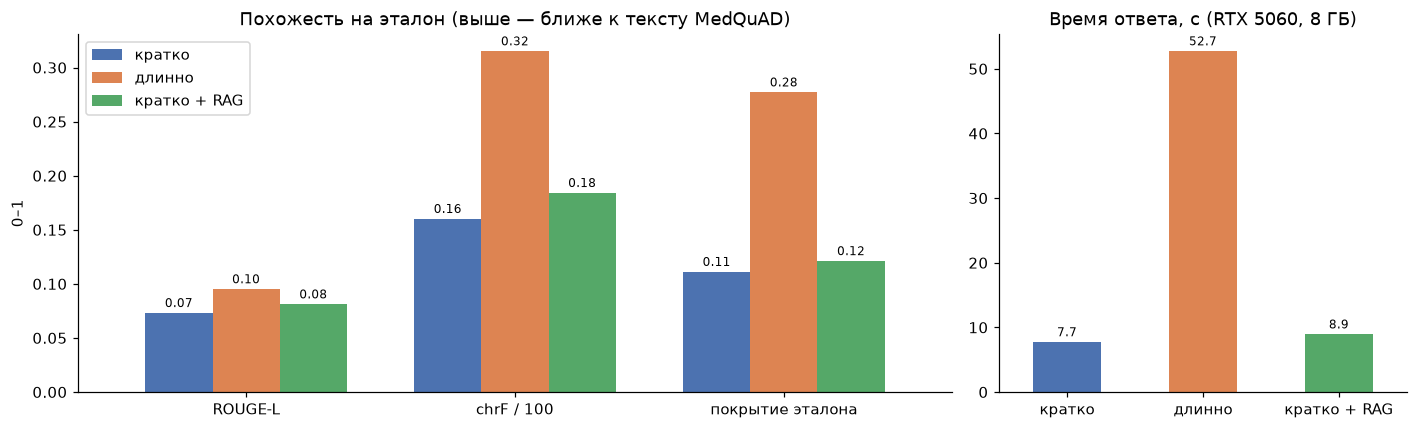

In [3]:
sim = table.loc[["ROUGE-L", "chrF", "покрытие эталона"]].copy()
sim.loc["chrF"] = sim.loc["chrF"] / 100          # chrF в шкале 0–100, остальные 0–1
sim = sim.rename(index={"chrF": "chrF / 100"})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1.4]})
sim.plot.bar(ax=axes[0], rot=0, color=[BLUE, ORANGE, GREEN], width=0.75)
axes[0].set_title("Похожесть на эталон (выше — ближе к тексту MedQuAD)")
axes[0].set_ylabel("0–1")
table.loc["время ответа, с"].plot.bar(ax=axes[1], rot=0, color=[BLUE, ORANGE, GREEN])
axes[1].set_title("Время ответа, с (RTX 5060, 8 ГБ)")
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f" if ax is axes[0] else "%.1f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

**Как читать.** Длинные ответы ближе к эталону по словам (chrF 31.5 против 16), но в 7 раз медленнее,
и 14 из 22 обрезаны лимитом токенов. Краткий режим быстрый (~8 с) и ни разу не обрезан.
Язык ответа совпал в 100% случаев во всех режимах.

## 2. Помогает ли RAG?

Честное сравнение — на **одних и тех же** 10 вопросах (строки 0–9, русский), с RAG и без.

,без RAG,с RAG,разница
ROUGE-L,0.074,0.081,0.007
chrF / 100,0.160,0.184,0.024
покрытие эталона,0.111,0.121,0.010
Jaccard,0.084,0.088,0.004


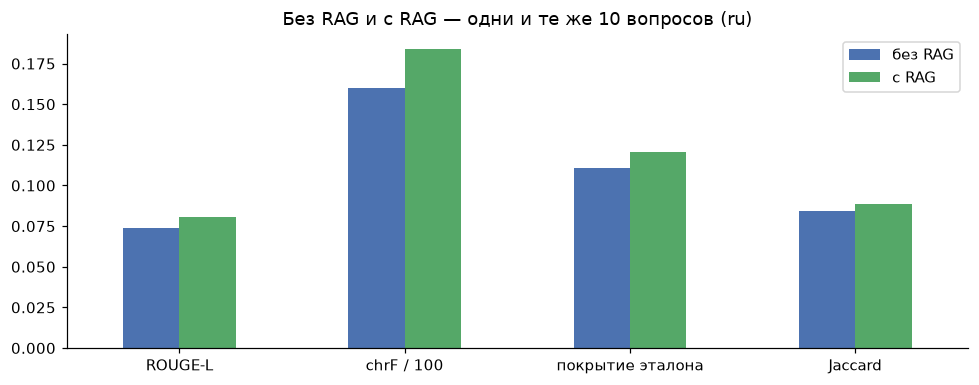

In [4]:
plain = pd.read_parquet(SALUKI_RESULTS / "metrics.parquet")
rag = pd.read_parquet(SALUKI_RESULTS / "metrics_rag.parquet")
plain = plain[plain["row"].isin(rag["row"]) & plain["lang"].isin(rag["lang"])]
cols = {"rougeL_f1": "ROUGE-L", "chrf": "chrF / 100", "reference_coverage": "покрытие эталона", "jaccard": "Jaccard"}
comp = pd.DataFrame({"без RAG": plain[list(cols)].mean(), "с RAG": rag[list(cols)].mean()}).rename(index=cols)
comp.loc["chrF / 100"] /= 100
comp["разница"] = comp["с RAG"] - comp["без RAG"]
display(comp.round(3))

ax = comp[["без RAG", "с RAG"]].plot.bar(rot=0, figsize=(9, 3.6), color=[BLUE, GREEN])
ax.set_title(f"Без RAG и с RAG — одни и те же {len(rag)} вопросов (ru)")
plt.tight_layout()
plt.show()

**Вывод:** прирост есть, но маленький (ROUGE-L 0.074 → 0.081) и на 10 вопросах он в пределах шума.
Чтобы утверждать, что RAG помогает, нужен прогон на 100–200 вопросах и по всем трём языкам:
`python -m medqa saluki run --limit 200 --shuffle --rag` и тот же прогон без `--rag`.

## 3. Новые вопросы (не из датасета)

20 вопросов на трёх языках. Эталона нет, поэтому проверяем язык ответа и время.

In [5]:
new = pd.read_parquet(SALUKI_RESULTS / "new_questions_answers.parquet").assign(режим="без RAG")
new_rag = pd.read_parquet(SALUKI_RESULTS / "new_questions_answers_rag.parquet").assign(режим="с RAG")
both = pd.concat([new, new_rag], ignore_index=True)
both["язык совпал"] = [detect_language(a) == lang for a, lang in zip(both["answer"], both["lang"])]
(both.groupby(["режим", "lang"])
     .agg(ответов=("id", "size"), **{"язык совпал, %": ("язык совпал", lambda s: round(100 * s.mean()))},
          **{"время, с": ("latency_s", "mean")})
     .round(1))

ответов  язык совпал, %  время, с
режим   lang                                   
без RAG en         20             100       6.5
        kk         20             100      10.7
        ru         20             100       6.9
с RAG   en         10             100       9.1
        kk         10             100      14.2
        ru         10             100       9.2

In [6]:
example = both[(both["id"] == 0)].sort_values(["lang", "режим"])
for _, r in example.iterrows():
    display(Markdown(f"**[{r['lang']}, {r['режим']}] {r['question']}**\n\n{r['answer']}"))

**[en, без RAG] What is hypertension?**

Hypertension, or high blood pressure, is a condition where the force of blood pushing against artery walls is consistently too high, often exceeding 130/80 mmHg. It is a major risk factor for heart disease, stroke, and kidney damage. While it is frequently asymptomatic, it can be detected through regular blood pressure monitoring. Always consult a qualified healthcare provider for proper diagnosis and personalized treatment plans.

**[en, с RAG] What is hypertension?**

Hypertension, commonly known as high blood pressure, is a condition where the force of blood pushing against the walls of your arteries is consistently too high. This extra pressure forces your heart to work harder to pump blood, which can damage blood vessels and lead to serious health problems over time. If left untreated, hypertension can increase the risk of heart disease, stroke, kidney damage, and other complications. It is often called the "silent killer" because it typically has no symptoms until it becomes severe.

**[kk, без RAG] Гипертония дегеніміз не?**

Гипертония – қан қысынының тұрақты түрде жоғары болуы. Бұл ауру қан тамырларына, жүрекке және бүйрекке зиян келтіреді. Дәрісіз емдеу қауіпті, сондықтан дәрігердің кеңесіне жүгінгеніңіз маңызды.

**[kk, с RAG] Гипертония дегеніміз не?**

Гипертония – бұлшықеттердің тым көп қатты болып, қозғалуы қиын болатын жағдай. Бұл көбінесе мидың немесе жұлынның зақымдануынан пайда болады. Ауру буындардың қозғалуын шектейді және кейде адамның құлауына әкеледі.

**[ru, без RAG] Что такое гипертония?**

Гипертония — это хроническое повышение артериального давления выше нормы. Высокое давление создает нагрузку на сердце и сосуды, что может привести к серьезным осложнениям, таким как инсульт или инфаркт. Для постановки диагноза и подбора лечения важно обратиться к врачу.

**[ru, с RAG] Что такое гипертония?**

Гипертония — это состояние, при котором мышечный тонус становится слишком высоким, что приводит к скованности и затруднению движений конечностей. Она возникает из-за повреждения областей головного или спинного мозга, которые регулируют сигналы для сокращения мышц. Причины могут включать инсульт, травмы, опухоли, нейродегенеративные заболевания или аномалии развития нервной системы. Тяжелая гипертония может ограничивать подвижность суставов и даже приводить к их «заморозке» (контрактурам).

## 4. medbot: потери на validation

Validation — 1437 вопросов × 3 языка, которых модель не видела при обучении. Чем ниже loss, тем увереннее
модель предсказывает эталонный ответ. Общий `eval_loss` посчитан тренером, по языкам — отдельным прогоном
по **всему диалогу** (вместе с вопросом), поэтому числа немного отличаются. Посчитать только по ответу:
`python -m medqa medbot eval --save`.

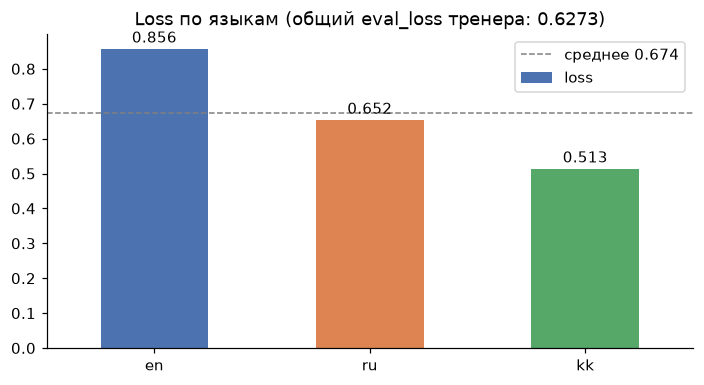

In [7]:
val = json.loads((MEDBOT_RESULTS / "validation_metrics.json").read_text(encoding="utf-8"))
per_lang = json.loads((MEDBOT_RESULTS / "validation_per_language.json").read_text(encoding="utf-8"))
losses = pd.Series({lang: per_lang[lang]["eval_loss"] for lang in ("en", "ru", "kk")}, name="loss")

ax = losses.plot.bar(rot=0, color=[BLUE, ORANGE, GREEN], figsize=(6.5, 3.6))
ax.axhline(per_lang["overall"], color="gray", ls="--", lw=1, label=f"среднее {per_lang['overall']:.3f}")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=2)
ax.set_title(f"Loss по языкам (общий eval_loss тренера: {val['eval_loss']:.4f})")
ax.legend()
plt.tight_layout()
plt.show()

Казахский получил самый низкий loss, но это не значит, что казахские ответы лучше: машинные переводы
на казахский более шаблонные, и их легче предсказывать. Качество языка должен оценить носитель и врач.

## 5. medbot: контрольные вопросы

6 вопросов, по 2 на язык (тест 7 ноября, до исправлений в генерации).

In [8]:
import re

log = (MEDBOT_RESULTS / "test_results.txt").read_text(encoding="utf-8")
blocks = re.findall(r"===== \[(\w+)\] Q: (.+?)\n(language-check: .+?)\nA: (.*?)(?=\n===== |\nLANGUAGE CHECK)", log, re.S)
smoke = pd.DataFrame([{
    "язык": lang, "вопрос": q,
    "язык ответа верный": "OK" in check.split("->")[1],
    "911 в ответе": "911" in a,
    "<think> в ответе": "<think>" in a,
    "ответ (начало)": re.sub(r"<think>\s*</think>\s*", "", a).strip()[:110] + "…",
} for lang, q, check, a in blocks])
smoke

,язык,вопрос,язык ответа верный,911 в ответе,<think> в ответе,ответ (начало)
0,en,What are the symptoms of type 2 diabetes?,True,False,True,What are the signs and symptoms of type 2 diabetes? The signs and symptoms of type 2 diabetes include increase…
1,en,How is high blood pressure treated?,True,False,True,"High blood pressure is treated with lifestyle changes, medicines, or a combination of the two. Lifestyle chang…"
2,ru,Что такое астма и какие у неё симптомы?,True,False,True,"Астма – это хроническое заболевание, которое вызывает проблемы с дыханием. При астме ваши дыхательные пути, ил…"
3,ru,"У меня сильная боль в груди, что мне делать?",True,True,True,"Если вы испытываете сильную боль в груди, немедленно позвоните 911. Не подождите, пока симптомы прошли.…"
4,kk,Диабет дегеніміз не?,True,False,True,Диабет - қандағы қанттың жоғары деңгейі. Бұл сіздің денеңіздің қантты қолдануына кедергі келтіреді. Қант - ағз…
5,kk,Жоғары қан қысымын қалай емдейді?,True,False,True,Жоғары қан қысымын қалай емдеуге болады? Жоғары қан қысымын тиімді емдеу келесі факторларға байланысты өзгеред…


**Что было не так и что исправлено в новом коде (`medqa/medbot.py`):**

- в каждом ответе оставался пустой блок `<think></think>` — теперь Qwen3 запускается с `enable_thinking=False`, а остатки вырезаются;
- на «боль в груди» по-русски модель советовала **911** (номер США) — теперь для ru/kk он заменяется на **103 или 112**;
- старая проверка писала «NO» на безопасный ответ «позвоните 911» — теперь звонок в экстренную службу засчитывается;
- ответ про давление повторял один фрагмент 4 раза — добавлен штраф за повторы (`repetition_penalty=1.1`).

Проверить заново на машине с GPU: `python -m medqa medbot test --save`.

## Итог

| | Saluki 27B | medbot (Qwen3-4B + LoRA) |
|---|---|---|
| обучение | нет (готовая модель) | 1 эпоха QLoRA на 12 931 × 3 примерах |
| размер | 7.9 ГБ (GGUF, 2 бита) | 137 МБ адаптер + базовая модель 3.4 ГБ |
| скорость на 8 ГБ GPU | ~8 с на краткий ответ | — |
| язык ответа | 100% | 6/6 |
| проверено | 50–60 ответов | 6 ответов + loss на 4311 примерах |

Обе модели — эксперимент: перед реальным использованием ответы должен проверить врач.